# 背景概述

学生版 · 本次作业需要完成任务 1.1、1.2、3.1、3.2 的四个函数，以及任务 3.3 和问题 4.1—4.3 的文字回答。
请在 `BEGIN YOUR SOLUTION` 与 `END YOUR SOLUTION` 之间作答。未填写的函数会提示 `NotImplementedError`，请按题目顺序完成后运行相应测试。

运行环境：推荐 Python 3.12；依赖见同目录的 `environment_minimal.yml`。
请先完整解压学生包，在 `hw2` 目录启动 Jupyter，使数据文件的相对路径正确。


$\quad$人的 (生物学) 性别由染色体上的若干基因决定. 本次上机作业中, 我们使用[GTEx组织基因表达数据库](https://www.gtexportal.org/home/downloads/adult-gtex/bulk_tissue_expression)中的人脑杏仁核 (amygdala) 数据子集, 应用Logistic回归模型, 从基因片段表达量出发, 预测测序样本对应被试的性别.

$\quad$在生物信息学中, 基因表达量常以[TPM (Transcript Per kilobase Million)](https://www.rna-seqblog.com/rpkm-fpkm-and-tpm-clearly-explained/) 进行记录. 给定被测样本$S$和基因片段$G$, 则TPM可由下述公式计算:
$$
\mathrm{TPM}(G; S) = 10^6 \frac{\mathrm{RPK}(G; S)}{\sum_G{\mathrm{RPK}(G; S)}},
$$
其中, **RPK (Reads Per Kilobase)** 是将样本$S$中 **基因$G$的表达 (转录) 计数值 (reads)** 按长度 (单位是 **千碱基 (kilobase, kb)** ) 做了归一化:
$$
\mathrm{RPK} (G; S) = \frac{\mathrm{ReadCount}(G; S)}{\mathrm{KbLength}(G)}.
$$
- 简言之, 基因$G$在测序样本$S$中的TPM值越高 (或说, RPK越高), 则基因$G$在$S$中的表达越"活跃".

# 数据的读取与清洗

$\quad$在数据文件`GTEx_gene_amygdala_tpm_v8.gct`中, 实际存有56200条基因片段在152份样本中的TPM值. 文件头仍标记为154列, 读取时以实际样本列为准.
- GTEx数据库给每份被测样本提供了[格式化的编码](https://gtexportal.org/home/faq#sampleIdFormat), 其中包括被测样本的供体 (人员) 编号`donor ID`;
- 我们将根据该文件中的测序数据预测供体人员的性别, 而这些供体人员 (包括性别在内) 的各种信息存于数据文件`subject_pheontypes_v8.txt`中.

## 基因测序数据

$\quad$**任务1**: 从`.gct`格式文件中读取测序数据, 并完成训练-测试拆分与归一化.
- **任务1.1**: 编写函数`read_gct()`, 完成原始数据的读取.
  - 输入: 数据文件名`gct_fname`.
  - 返回: 读取完的数据`raw_data`, 格式为`pd.DataFrame`. 要求:
    - 以名称列`Name`作为表格索引, 以备后续检索性别时使用.
    - 先将`id`和`Description`两列从原表格中删除, 再将原表格 **转置**.
- **任务1.2**: 编写函数`normalize_tpms()`, 完成 (拆分后的) 原始数据的归一化.
  - 输入:
    - 训练集`X_train`;
    - 其它数据集`others`, 以列表打包起来;
    - 归一化方法`method`, 仅接受两个可能值: `'minmax'`和`'standard'`, 分别代表**最小-最大**归一化和**均值-方差**归一化.
  - 返回: 经过归一化处理的`X_train_normalized`以及其它数据集`others_normalized`(以列表打包起来). **为了和[`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler)或[`MinMaxScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html#sklearn.preprocessing.MinMaxScaler)保持一致, 请确保返回值均为`np.ndarray`格式**, 例如对某`DataFrame`类型的变量`df`使用格式转换`np.array(df)`.

### 提示
- [GCT](https://clue.io/connectopedia/pdf/gct_format)是一种常用的测序数据文件记录格式, 大致如下:
```
#(version string)
(data row count) (tab) (data column count) (tab) (row metadata field count) (tab) (column metadata field count)
Name (tab) Description (tab) (sample 1 name) (tab) ...
(gene 1 name) (tab) (gene 1 description) (tab) (TPM of sample 1 on gene 1) (tab) ...
```
例如: 本例的数据文件`GTEx_gene_amygdala_tpm_v8.gct`的前4行为
```
#1.3
56200	154	0	0
id	Name	Description	GTEX-11NUK-0011-R4a-SM-DO12B	GTEX-11ONC-0011-R4b-SM-DO93H ...
0	ENSG00000223972.5	DDX11L1	0.0718	0.0000 ...
```
- 在编写函数`read_gct`时, 你需要从[`pd.read_csv()`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html#pandas.read_csv)函数中仔细地寻找你需要的特定参数, 以适应`.gct`数据格式. 这里需要额外指定的参数包括分隔符`sep`和跳过的行数`skiprows`.
  - CSV文件的全称是[Comma-Separated Values](https://en.wikipedia.org/wiki/Comma-separated_values), 所以, `pd.read_csv()`函数默认采用的数据分隔符是逗号`','`. 但GCT文件采用制表符`'\t'`作为分隔符.
  - 我们需要第3行的内容作为`DataFrame`的列索引, 而正式记录的数据从第4行开始. 前两行是非格式化的, 且并非我们必须读入的信息.
- `.gct`文件每行记录一个特定的基因名(特征), 每列记录一个被试试验 (被试性别的数据将从另外渠道读取). 根据`sklearn`的数据矩阵格式要求, 需要用[`transpose()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.transpose.html#pandas.DataFrame.transpose)方法取原表格的转置.
- 基因编号储存在`Name`列中, 需要使用[`set_index()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.set_index.html#pandas.DataFrame.set_index)将它设置为索引. 转置后, 基因编号成为列名, 原表格中的样本编号成为行索引, 用于和性别信息对接.

In [1]:
from pathlib import Path

import pandas as pd

DATA_DIR = Path("mlchem-2024fall_v1")


def read_gct(gct_fname: str | Path) -> pd.DataFrame:
    ### BEGIN YOUR SOLUTION ###
    data = pd.read_csv(gct_fname, sep="\t", skiprows=2, index_col="Name")
    return data.drop(columns=["id", "Description"]).T
    ### END YOUR SOLUTION ###


$\quad$完成任务1.1后, 请运行下面的代码块做初步检查.

In [2]:
### SANITY CHECK CELL 1.1 ###
### EXPECTED OUTPUT ###
'''

Name	ENSG00000223972.5	ENSG00000227232.5	ENSG00000278267.1	ENSG00000243485.5	ENSG00000237613.2
GTEX-11NUK-0011-R4a-SM-DO12B	0.0718	0.7852	0.0	0.1147	0.0204
GTEX-11ONC-0011-R4b-SM-DO93H	0.0000	0.9886	0.0	0.0000	0.0000
'''
gct = read_gct(DATA_DIR / "GTEx_gene_amygdala_tpm_v8.gct")
gct.iloc[:2, :5]

Name,ENSG00000223972.5,ENSG00000227232.5,ENSG00000278267.1,ENSG00000243485.5,ENSG00000237613.2
GTEX-11NUK-0011-R4a-SM-DO12B,0.0718,0.7852,0.0,0.1147,0.0204
GTEX-11ONC-0011-R4b-SM-DO93H,0.0000,0.9886,0.0,0.0000,0.0000


In [3]:
gct.index

Index(['GTEX-11NUK-0011-R4a-SM-DO12B', 'GTEX-11ONC-0011-R4b-SM-DO93H',
       'GTEX-11PRG-0011-R4a-SM-DNZZR', 'GTEX-11TTK-0011-R4a-SM-DNZZU',
       'GTEX-11ZU8-0011-R4a-SM-5BC6Y', 'GTEX-11ZVC-0011-R4a-SM-5BC6Z',
       'GTEX-12WSA-0011-R4a-SM-57WB7', 'GTEX-12WSD-0011-R4b-SM-5LZUA',
       'GTEX-12WSF-0011-R4b-SM-5HL88', 'GTEX-12WSH-0011-R4a-SM-5GU6K',
       ...
       'GTEX-X4EP-0011-R4B-SM-3P627', 'GTEX-X4XX-0011-R4B-SM-46MWL',
       'GTEX-X585-0011-R4B-SM-46MVH', 'GTEX-XLM4-0011-R4B-SM-4AT5C',
       'GTEX-Y8DK-0011-R4A-SM-EXUR1', 'GTEX-YFC4-0011-R4a-SM-4RGLQ',
       'GTEX-ZAB4-0011-R4a-SM-4SOKB', 'GTEX-ZAK1-0011-R4a-SM-6AJBK',
       'GTEX-ZE9C-0011-R4a-SM-4WKH6', 'GTEX-ZVZQ-0011-R4b-SM-57WCZ'],
      dtype='str', length=152)

$\quad$检查完成后, 你可以继续完成任务1.2: 对拆分完成的数据集进行归一化.

In [4]:
from collections.abc import Sequence
from typing import Any, Literal

import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler


def normalize_tpms(
    X_train: pd.DataFrame | np.ndarray,
    others: Sequence[pd.DataFrame | np.ndarray],
    method: Literal["minmax", "standard"],
) -> tuple[np.ndarray, list[np.ndarray]]:
    ### BEGIN YOUR SOLUTION ###
    scaler_classes = {"minmax": MinMaxScaler, "standard": StandardScaler}
    if method not in scaler_classes:
        raise ValueError(f"Unknown normalization method: {method!r}")
    scaler = scaler_classes[method]()
    X_train_normalized = scaler.fit_transform(np.asarray(X_train))
    others_normalized = [scaler.transform(np.asarray(other)) for other in others]
    return X_train_normalized, others_normalized
    ### END YOUR SOLUTION ###


$\quad$完成任务1.2后, 可以运行下面的代码块对该函数进行测试. 测试情况将关系到该任务的得分. **请勿修改代码块中的任何内容**.

In [5]:
### TEST CELL 1 ###
### CAUTION: DO NOT MODIFY THIS CELL. ###

test_X_train = np.random.randn(100, 5)
test_others = np.random.randn(10, 50, 5)

def test_standardscale_train(X_train):
    X_train, _ = normalize_tpms(X_train, [], method='standard')
    np.testing.assert_allclose(
        X_train.mean(axis=0), np.zeros(5), atol=1.0e-5,
        err_msg="invalid X_train normalization: non-zero mean."
    )
    np.testing.assert_allclose(
        X_train.std(axis=0), np.ones(5), rtol=1.0e-3,
        err_msg="invalid X_train normalization: non-unit std."
    )

def test_standardscale_consistency(X_train, others):
    X_train_mean, X_train_std = X_train.mean(axis=0), X_train.std(axis=0)
    X_train, others_normalized = normalize_tpms(X_train, [*others], method='standard')
    for other, other_normalized in zip(others, others_normalized):
        mean_normalized = (other.mean(axis=0) - X_train_mean) / X_train_std
        std_normalized = other.std(axis=0) / X_train_std
        np.testing.assert_allclose(
            other_normalized.mean(axis=0), mean_normalized, atol=1.0e-5,
            err_msg="inconsistent normalization: didn't use the training mean correctly."
        )
        np.testing.assert_allclose(
            other_normalized.std(axis=0), std_normalized, rtol=1.0e-3,
            err_msg="inconsistent normalization: didn't use the training std correctly."
        )

def test_minmaxscale_train(X_train):
    X_train, _ = normalize_tpms(X_train, [], method='minmax')
    np.testing.assert_allclose(
        X_train.min(axis=0), np.zeros(5), atol=1.0e-5,
        err_msg="invalid X_train normalization: min not equal to zero."
    )
    np.testing.assert_allclose(
        X_train.max(axis=0), np.ones(5), rtol=1.0e-3,
        err_msg="invalid X_train normalization: max not equal to one."
    )

def test_minmaxscale_consistency(X_train, others):
    X_train_min, X_train_max = X_train.min(axis=0), X_train.max(axis=0)
    X_train, others_normalized = normalize_tpms(X_train, [*others], method='minmax')
    for other, other_normalized in zip(others, others_normalized):
        min_normalized = (other.min(axis=0) - X_train_min) / (X_train_max - X_train_min)
        max_normalized = (other.max(axis=0) - X_train_min) / (X_train_max - X_train_min)
        np.testing.assert_allclose(
            other_normalized.min(axis=0), min_normalized, atol=1.0e-5,
            err_msg="inconsistent normalization: didn't use the training min correctly."
        )
        np.testing.assert_allclose(
            other_normalized.max(axis=0), max_normalized, rtol=1.0e-3,
            err_msg="inconsistent normalization: didn't use the training max correctly."
        )

try:
    print("training set standard scale:", end=" ")
    test_standardscale_train(test_X_train)
    print("PASSED")
except Exception as err:
    print(err)

try:
    print("standard scale consistency:", end=" ")
    test_standardscale_consistency(test_X_train, test_others)
    print("PASSED")
except Exception as err:
    print(err)

try:
    print("training set minmax scale:", end=" ")
    test_minmaxscale_train(test_X_train)
    print("PASSED")
except Exception as err:
    print(err)

try:
    print("minmax scale consistency:", end=" ")
    test_minmaxscale_consistency(test_X_train, test_others)
    print("PASSED")
except Exception as err:
    print(err)

training set standard scale: PASSED
standard scale consistency: PASSED
training set minmax scale: PASSED
minmax scale consistency: PASSED


## 供体性别数据

$\quad$我们已经为你准备好相关代码, 根据`.gct`数据中的被测供体编号, 从`subject_pheontypes_v8.txt`中提取对应的性别信息. 原始数据以1标记男性 (male)、2标记女性 (female), 这里改用0标记男性、1标记女性, 和Logistic回归模型的0-1分类习惯一致. 请运行下述两个代码块, 读取被测供体的性别数据.

In [6]:
def get_gender(
    annot_fname: str | Path, gtex_ids: Sequence[str], sep: str = "\t"
) -> pd.Series:
    gtex_subjids = ["-".join(gtex_id.split("-")[:2]) for gtex_id in gtex_ids]
    annot = pd.read_csv(annot_fname, sep=sep).set_index("SUBJID")
    return annot.loc[gtex_subjids, "SEX"] - 1


In [7]:
gender = get_gender(
    DATA_DIR / "subject_pheontypes_v8.txt", gtex_ids=list(gct.index)
)
gender


SUBJID
GTEX-11NUK    0
GTEX-11ONC    0
GTEX-11PRG    0
GTEX-11TTK    1
GTEX-11ZU8    0
             ..
GTEX-YFC4     1
GTEX-ZAB4     0
GTEX-ZAK1     1
GTEX-ZE9C     0
GTEX-ZVZQ     1
Name: SEX, Length: 152, dtype: int64

$\quad$**任务2**: 轻松一下! 运行下面的代码块, 查看供体的性别比例饼图.

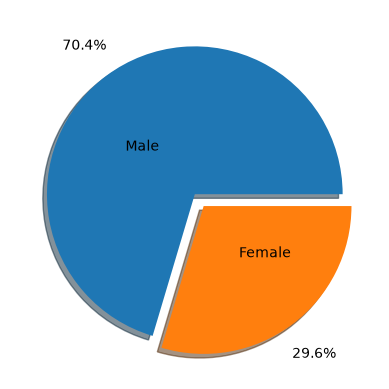

In [8]:
gender_counts = gender.value_counts().reindex([0, 1], fill_value=0)
gender_counts = gender_counts.rename(index={0: "Male", 1: "Female"})
_ = gender_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    pctdistance=1.25,
    labeldistance=0.4,
    shadow=True,
    explode=[0, 0.1],
)


# 模型的训练与评估

$\quad$我们下面搭建Logistic回归模型, 并逐步完成模型训练与评估的全部流程. 请先运行下述代码块, 完成数据集的初步拆分.

In [9]:
from sklearn.model_selection import train_test_split
test_size = 0.2
random_state = 0
X_train, X_test, y_true_train, y_true_test = train_test_split(gct, gender, test_size=test_size, random_state=random_state)

$\quad$**任务3**: 模型训练与评估组件的搭建.
- **任务3.1**: 编写函数`evaluate_model()`, 实现模型评估.
  - 输入:
    - 真实标签构成的列表`y_trues`、预测标签构成的列表`y_preds`、预测概率分值构成的列表`y_probas`;
    - 图例标注构成的列表`labels`;
    - `plot`: `bool`值参数 (默认为`True`), 表征在调用该函数是否作ROC曲线.
  - 返回: 以字典形式返回各个数据集上的分类指标. 示例:
  ```
  Input parameters:
      evaluate_model(
          y_trues=[y_true_train, y_true_test],
          y_preds=[y_pred_train, y_pred_test],
          y_probas=[y_proba_train, y_proba_test],
          labels=['train', 'test'],
          plot=True
      )
  Returned value:
      {
          'accuracy': [accuracy_train, accuracy_test],
          'precision': [precision_train, precision_test],
          'recall': [recall_train, recall_test],
          'f1': [f1_train, f1_test]
      }
  ```
  - 需实现的其它功能:
    - 如果`plot=True`, 则要求该函数能够应用函数`plot_roc()` (参见上机实习2, 以下已给出) 绘制各个数据集上的ROC曲线, 并以图例的形式报告对应的AUC值.

- **任务3.2**: 编写函数`train_and_eval()`, 建立模型训练与评估的工作流.
  - 输入:
    - 训练与验证数据集: `X_train, X_val, y_true_train, y_true_val`;
    - 是否在评估时进行ROC作图的逻辑参数`plot`;
    - 用于构建Logistic回归模型的超参数字典`hyperparams`.
  - 返回:
    - 训练好的模型`clf`;
    - 对应的评估指标字典`metrics`.

- **任务3.3**: 比较最小-最大归一化与均值-方差归一化带来的训练效果.

### 提示
- 对字典使用`**`运算符, 可以将其作为一组[关键词参数 (kwargs)](https://www.pythontutorial.net/python-basics/python-kwargs/) 传入特定函数. 例如:
```python
from typing import Any

def train_model(X_train: np.ndarray, y_true_train: np.ndarray, hyperparams: dict[str, Any]) -> object:
    return LogisticRegression(**hyperparams).fit(X_train, y_true_train)
```
- 注意[`predict_proba()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression.predict_proba)方法将对每条数据返回包含两个类别概率的一行数组, 我们需要的是第二个值 (即让模型决策为`1`而非`0`的那个概率).

In [10]:
from matplotlib import pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
def plot_roc(y_trues, y_probas, labels):
    # figure setup
    plt.title("ROC curve of the Logistic Regression model")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    for y_true, y_proba, label in zip(y_trues, y_probas, labels):
        # metrics preparation
        fpr, tpr, _ = roc_curve(y_true, y_proba)
        auc = roc_auc_score(y_true, y_proba)
        plt.plot(fpr, tpr, label=f"{label} AUC = {auc:.2f}")
    plt.legend()
    plt.show()

In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


def evaluate_model(
    y_trues: Sequence[np.ndarray | pd.Series | pd.DataFrame],
    y_probas: Sequence[np.ndarray | pd.Series | pd.DataFrame],
    y_preds: Sequence[np.ndarray | pd.Series | pd.DataFrame],
    labels: Sequence[str],
    plot: bool = True,
) -> dict[str, list[float]]:
    ### BEGIN YOUR SOLUTION ###
    metrics = {"accuracy": [], "precision": [], "recall": [], "f1": []}
    for y_true, y_pred in zip(y_trues, y_preds, strict=True):
        metrics["accuracy"].append(accuracy_score(y_true, y_pred))
        metrics["precision"].append(precision_score(y_true, y_pred, zero_division=0))
        metrics["recall"].append(recall_score(y_true, y_pred, zero_division=0))
        metrics["f1"].append(f1_score(y_true, y_pred, zero_division=0))
    if plot:
        plot_roc(y_trues, y_probas, labels)
    return metrics
    ### END YOUR SOLUTION ###


$\quad$完成任务3.1后, 可以运行下面的代码块对该函数进行测试. 测试情况将关系到该任务的得分. **请勿修改代码块中的任何内容**.

In [12]:
### TEST CELL 3.1 ###
### CAUTION: DO NOT MODIFY THIS CELL. ###

test_y_trues = [np.array([0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1])]
test_y_preds = [np.array([0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1])]
test_metrics = [0.4666666666666667, 0.5, 0.375, 0.42857142857142855]

def test_evaluate_model_keys(y_trues, y_preds, test_metrics):
    metrics = evaluate_model(y_trues, [], y_preds, [], plot=False)
    assert set(metrics.keys()) == {"accuracy", "precision", "recall", "f1"}, "wrong metrics names."

def test_evaluate_model_values(y_trues, y_preds, test_metrics):
    metrics = evaluate_model(y_trues, [], y_preds, [], plot=False)
    np.testing.assert_allclose(
        [metrics["accuracy"][0], metrics["precision"][0], metrics["recall"][0], metrics["f1"][0]], test_metrics, rtol=1.0e-3,
        err_msg="wrong metrics values."
    )

try:
    print("keys:", end=" ")
    test_evaluate_model_keys(test_y_trues, test_y_preds, test_metrics)
    print("PASSED")
except Exception as err:
    print(err)

try:
    print("values:", end=" ")
    test_evaluate_model_values(test_y_trues, test_y_preds, test_metrics)
    print("PASSED")
except Exception as err:
    print(err)

keys: PASSED
values: PASSED


$\quad$测试通过后, 你可以继续完成任务3.2: `train_and_eval()`函数的编写.

In [13]:
from sklearn.linear_model import LogisticRegression


def train_and_eval(
    X_train: np.ndarray | pd.DataFrame,
    X_val: np.ndarray | pd.DataFrame,
    y_true_train: np.ndarray | pd.Series | pd.DataFrame,
    y_true_val: np.ndarray | pd.Series | pd.DataFrame,
    hyperparams: dict[str, Any],
    plot: bool = True,
) -> tuple[LogisticRegression, dict[str, list[float]]]:
    ### BEGIN YOUR SOLUTION ###
    clf = LogisticRegression(**hyperparams).fit(X_train, np.asarray(y_true_train).ravel())
    datasets = [X_train, X_val]
    metrics = evaluate_model(
        y_trues=[y_true_train, y_true_val],
        y_probas=[clf.predict_proba(X)[:, 1] for X in datasets] if plot else [],
        y_preds=[clf.predict(X) for X in datasets],
        labels=["train", "val"],
        plot=plot,
    )
    return clf, metrics
    ### END YOUR SOLUTION ###


$\quad$完成任务3.2后, 请运行下面的代码块以做检查.

输出数值仅供参考；不同软件版本的优化结果可能略有差异。

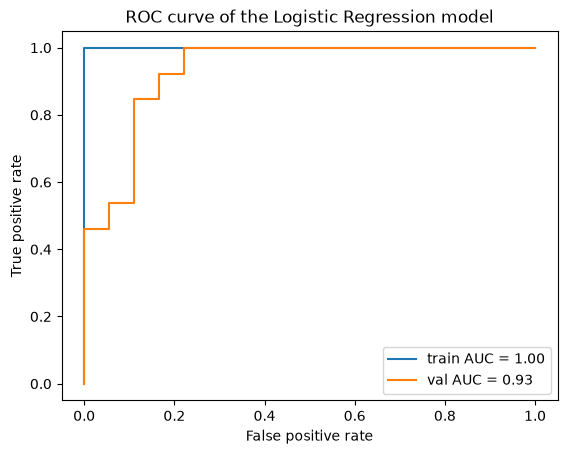

{'accuracy': [1.0, 0.7096774193548387],
 'precision': [1.0, 1.0],
 'recall': [1.0, 0.3076923076923077],
 'f1': [1.0, 0.47058823529411764]}

In [14]:
### SANITY CHECK CELL 3.2 ###
### EXPECTED OUTPUT ###
'''
{'accuracy': [1.0, 0.7096774193548387],
 'precision': [1.0, 1.0],
 'recall': [1.0, 0.3076923076923077],
 'f1': [1.0, 0.47058823529411764]}
'''

hyperparams = {'C': 0.5, 'class_weight': 'balanced', 'max_iter': 1000}
X_train_minmax, X_test_minmax = normalize_tpms(X_train, [X_test], method='minmax')
X_test_minmax = X_test_minmax[0]
clf_minmax, metrics_minmax = train_and_eval(X_train_minmax, X_test_minmax, y_true_train, y_true_test, hyperparams)
metrics_minmax

通过检查后, 你可以继续完成任务3.3: 运行下面的代码块, 比较最小-最大归一化与均值-方差归一化的优劣, 并简要说明你的解释 (提示: 回顾TPM的含义).

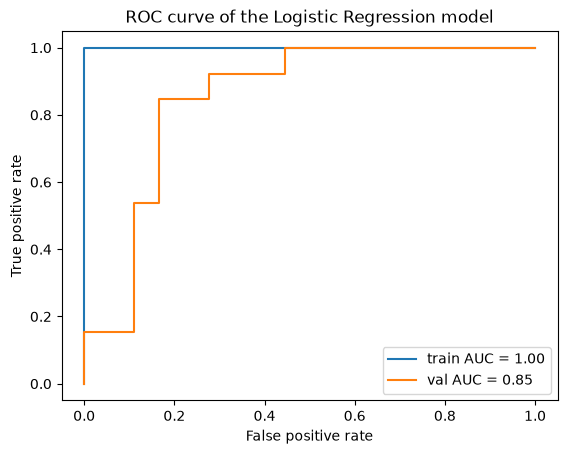

{'accuracy': [1.0, 0.6451612903225806],
 'precision': [1.0, 1.0],
 'recall': [1.0, 0.15384615384615385],
 'f1': [1.0, 0.26666666666666666]}

In [15]:
X_train_standard, X_test_standard = normalize_tpms(X_train, [X_test], method='standard')
X_test_standard = X_test_standard[0]
clf_standard, metrics_standard = train_and_eval(X_train_standard, X_test_standard, y_true_train, y_true_test, hyperparams)
metrics_standard

### 任务3.3答题区(另起一行时请记得加注释符号#) ###
### BEGIN YOUR SOLUTION ###
# 同一数据拆分和模型超参数下，两种方法的训练集准确率和 F1 均为 1.000。
# 测试集上，最小-最大归一化的准确率、查全率、F1 和 AUC 分别为 0.710、0.308、0.471、0.932；
# 均值-方差标准化对应为 0.645、0.154、0.267、0.850，两种方法的查准率均为 1.000。
# 默认阈值下，两者分别找出 13 份女性样本中的 4 份和 2 份，最小-最大归一化漏判较少。
# TPM 是单个样本内按转录本长度和总量校正的相对表达量，常有大量零值，不同基因的分布也不同。
# 最小-最大归一化将每个基因的训练集极差统一为 1；标准化则将训练集标准差统一为 1，
# 可能放大低方差基因的波动。两者会改变各基因在 L2 正则化下的相对权重，影响泛化表现。
# 这一结果基于 31 个测试样本和固定的 C 值。若要判断结果是否稳定，可在训练集内做分层交叉验证。
### END YOUR SOLUTION ###

# 结果分析: 对性别预测起决定作用的基因片段

**任务4**: 运行下述四个代码块, 根据Logistic回归模型系数, 筛选出对性别预测作用最大的5个基因片段.
- **问题4.1**: 筛选出系数最小 (最"负") 的5个系数所对应的基因名, 并自行检索相关信息. 它们大多定位在哪条染色体上? 这是否与生物学常识相符?
- **问题4.2**: 筛选出系数最大 (最"正") 的5个系数所对应的基因名, 并自行检索相关信息. 系数最大的那个基因片段如何与对应性别相关联?
- **问题4.3**: 某同学根据数据得出结论: **系数 (绝对) 值最大的5个基因片段对性别起决定作用**. 从生物学机制的角度, 这句话不一定合理, 为什么?

### 提示
- 为了回答问题4.1和4.2, 你可能需要检索一些基因组数据库, 例如 [Ensembl](https://www.ensembl.org/index.html)与[HGNC](https://www.genenames.org/).
- 为了回答问题4.2, 你可能需要一些[参考文献](https://pubmed.ncbi.nlm.nih.gov/16146776/)与[参考资料](https://en.wikipedia.org/wiki/X-inactivation).
- 为了回答问题4.3, 以下是一些帮助你思考的提示:
  - 所用数据集是否足够反映人体基因组?
  - 所用数据集各特征之间的独立性怎样? 以[SRY基因](http://asia.ensembl.org/Homo_sapiens/Gene/Summary?db=core;g=ENSG00000184895;r=Y:2786855-2787682;t=ENST00000383070)为例, 是否存在 **内生性** ([互为因果](https://www.ncbi.nlm.nih.gov/books/NBK9967/#:~:text=This%20gene%20is%20called%20SRY,and%20from%20many%20XY%20females.)) 的危险? (运行最后一个代码块)
  - 在这个数据集上的Logistic模型训练中, 是否有比L2正则化更好的选择、为什么?

In [16]:
coefs = clf_minmax.coef_[0]

In [17]:
male_idx = coefs.argsort()[:5]
coefs[male_idx], gct.columns[male_idx]

### 问题4.1答题区(另起一行时请记得加注释符号#) ###
### BEGIN YOUR SOLUTION ###
# 按系数从小到大排列，前 5 个基因为 TTTY15（-0.14336）、TTTY14（-0.13483）、
# RPS4Y1（-0.13104）、NLGN4Y（-0.12721）和 USP9Y（-0.12026）。
# GENCODE v26 将这 5 个基因都注释在 Y 染色体上，与通常的 XY 男性、XX 女性染色体组成相符。
# 本题女性标为 1、男性标为 0，因此在其余特征固定时，这些基因表达越高，女性分类的对数几率越低。
# 基因与染色体注释 https://www.gencodegenes.org/human/release_26.html
### END YOUR SOLUTION ###

(array([-0.14336387, -0.13483186, -0.13104216, -0.1272109 , -0.12026342]),
 Index(['ENSG00000233864.7', 'ENSG00000176728.7', 'ENSG00000129824.15',
        'ENSG00000165246.13', 'ENSG00000114374.12'],
       dtype='str', name='Name'))

In [18]:
female_idx = coefs.argsort()[-5:]
coefs[female_idx], gct.columns[female_idx]

### 问题4.2答题区(另起一行时请记得加注释符号#) ###
### BEGIN YOUR SOLUTION ###
# 按系数从大到小排列，前 5 个基因为 XIST（+0.05906，X 染色体）、JPX（+0.05254，X 染色体）、
# HMGN1P8（+0.05091，3 号）、SLCO1B3（+0.04887，12 号）和 RNA5SP111（+0.04849，2 号）。
# XIST 编码长链非编码 RNA，主要从将要失活或已失活的 X 染色体上转录，并参与招募沉默机制。
# 典型 XX 女性体细胞有一条失活的 X，典型 XY 男性体细胞通常没有失活的 X。
# 因此杏仁核样本中 XIST 表达较高会为女性标签（1）提供预测信号，与其正系数相符。
# 基因与染色体注释 https://www.gencodegenes.org/human/release_26.html
# XIST 的失活 X 表达 Brown 等（1991）https://www.nature.com/articles/349038a0
### END YOUR SOLUTION ###

(array([0.04848506, 0.04886781, 0.05090713, 0.05254158, 0.05905786]),
 Index(['ENSG00000223318.1', 'ENSG00000111700.12', 'ENSG00000241120.1',
        'ENSG00000225470.7', 'ENSG00000229807.10'],
       dtype='str', name='Name'))

In [19]:
SRY_idx = 55638
coefs[SRY_idx]

### 问题4.3答题区(另起一行时请记得加注释符号#) ###
### BEGIN YOUR SOLUTION ###
# 这批样本来自 152 份成人杏仁核组织，TPM 反映该组织当时的转录水平，无法覆盖胚胎性腺发育的时序和调控。
# 性染色体组成可以同时影响性别发育和多个基因的表达；已经形成的性别差异也可反过来影响成人组织表达。
# 因而有些高权重基因只是下游标志物或与其他特征共表达，单凭回归系数不足以推断其因果作用。
# 例如，SRY 参与胚胎期睾丸分化，但它在此模型中的系数约为 -0.04445，未进入最负的前 5 位。
# 系数还受归一化、正则化和共线性影响。L2 往往会让相关基因分摊权重，加上特征远多于样本，排名可能不稳定。
# 若目标是筛选较少的候选基因，可以用分层交叉验证比较 L1 或 Elastic Net，以检验预测性能和入选稳定性。
# L1 能得到稀疏模型，Elastic Net 可以保留部分相关特征。验证发育机制仍需独立样本及功能证据。
### END YOUR SOLUTION ###

np.float64(-0.04444624766351285)